# Inteligencia Artificial con Aplicaciones en Economía I

- Profesora: Lina María Castro
- Universidad Externado de Colombia, Facultad de Economía
- Integrantes: Daniel Peña, Santiago González y Sebastián Mendoza

# Etapa 1. Importación, limpieza y unión de las seis fuentes

## Importar librerías

In [1]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## Mejorar visualización de los dataframes y los gráficos

In [2]:
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

## Establecer la ruta de los datasets

In [3]:
ARCHIVO_CLAVE = os.path.join('data', 'raw', 'men_educacion_municipal.csv')

def buscar_proyecto(raices, niveles=4):
    for raiz in raices:
        for n in range(niveles + 1):
            hallados = glob.glob(os.path.join(raiz, *(['*'] * n), ARCHIVO_CLAVE))
            if hallados:
                return hallados[0].replace(os.sep + ARCHIVO_CLAVE, '')
    return None

try:
    from google.colab import drive
    drive.mount('/content/drive')
    path = buscar_proyecto(['/content/drive/MyDrive', '/content'])
    if path is None:
        zips = glob.glob('/content/drive/MyDrive/**/proyecto_desercion_coca*.zip', recursive=True)
        if zips:
            zipfile.ZipFile(zips[0]).extractall('/content')
            path = buscar_proyecto(['/content'])
    if path is None:
        raise FileNotFoundError("Suba a 'Mi unidad' la carpeta proyecto_desercion_coca y vuelva a correr la celda.")
    os.chdir(path)
except ImportError:
    if not os.path.exists(ARCHIVO_CLAVE) and os.path.exists(os.path.join('..', ARCHIVO_CLAVE)):
        os.chdir('..')

for carpeta in ['data/processed', 'outputs/figures', 'outputs/reports']:
    os.makedirs(carpeta, exist_ok=True)

print("Carpeta de trabajo:", os.getcwd())
print("Archivos en data/raw:", sorted(os.listdir('data/raw')))

Carpeta de trabajo: /home/claude/out/proyecto_desercion_coca
Archivos en data/raw: ['.gitkeep', 'coca_hectareas_municipal.csv', 'coca_hectareas_municipal_metadata.json', 'ipm_municipal_2018.xlsx', 'men_educacion_municipal.csv', 'men_educacion_municipal_metadata.json', 'municipios_pdet.csv', 'municipios_pdet_metadata.json', 'poblacion_municipal_area_2018_2042.xlsx', 'ruv_muestra_cruda.csv', 'ruv_victimas_metadata.json', 'ruv_victimas_municipio_anio.csv']


## Cargar los datasets

In [4]:
df_men = pd.read_csv('data/raw/men_educacion_municipal.csv', dtype=str)
df_coca = pd.read_csv('data/raw/coca_hectareas_municipal.csv', dtype=str)
df_victimas = pd.read_csv('data/raw/ruv_victimas_municipio_anio.csv', dtype=str)
df_victimas_muestra = pd.read_csv('data/raw/ruv_muestra_cruda.csv', dtype=str)
df_pdet = pd.read_csv('data/raw/municipios_pdet.csv', dtype=str)

archivo_ipm = 'data/raw/ipm_municipal_2018.xlsx'
df_ipm = pd.read_excel(archivo_ipm, sheet_name='2_IPM Mpio y Dpt', dtype={'ID': str})
df_ipm_zona = pd.read_excel(archivo_ipm, sheet_name='4_IPM Mpio dominios', dtype={'ID': str})
df_privaciones = pd.read_excel(archivo_ipm, sheet_name='6_Privaciones IPM Dpt-Mpio', header=1, dtype={'ID': str})
df_privaciones_zona = pd.read_excel(archivo_ipm, sheet_name='8_Privaciones Mpio dominio', header=[0, 1])

df_poblacion = pd.read_excel('data/raw/poblacion_municipal_area_2018_2042.xlsx',
                             sheet_name='PobMunicipalxÁrea', header=7, dtype={'MPIO': str})

print("Hojas del archivo del IPM:", pd.ExcelFile(archivo_ipm).sheet_names)
print("Hojas del archivo de población:", pd.ExcelFile('data/raw/poblacion_municipal_area_2018_2042.xlsx').sheet_names)

Hojas del archivo del IPM: ['2_IPM Mpio y Dpt', '4_IPM Mpio dominios', '6_Privaciones IPM Dpt-Mpio', '8_Privaciones Mpio dominio', 'TB_REF', 'Visor']
Hojas del archivo de población: ['Índice', 'PPED', 'PobMunicipalxÁrea']


## Exploración inicial de los datasets

In [5]:
bases = {'MEN': df_men, 'Coca (SIMCI)': df_coca, 'Víctimas (RUV, agregada)': df_victimas,
         'Víctimas (RUV, muestra cruda)': df_victimas_muestra, 'PDET': df_pdet, 'IPM': df_ipm,
         'IPM por zona': df_ipm_zona, 'Privaciones IPM': df_privaciones,
         'Privaciones IPM por zona': df_privaciones_zona, 'Población por área': df_poblacion}

pd.DataFrame({'Base': list(bases.keys()),
              'Filas': [b.shape[0] for b in bases.values()],
              'Columnas': [b.shape[1] for b in bases.values()]})

,Base,Filas,Columnas
0,MEN,15707,41
1,Coca (SIMCI),319,28
2,"Víctimas (RUV, agregada)",2997,4
3,"Víctimas (RUV, muestra cruda)",2000,16
4,PDET,170,6
5,IPM,1122,3
6,IPM por zona,1122,5
7,Privaciones IPM,1122,17
8,Privaciones IPM por zona,1122,47
9,Población por área,84234,7


In [6]:
df_men.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15707 entries, 0 to 15706
Data columns (total 41 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   a_o                          15707 non-null  object
 1   c_digo_municipio             15707 non-null  object
 2   municipio                    15707 non-null  object
 3   c_digo_departamento          15707 non-null  object
 4   departamento                 15707 non-null  object
 5   c_digo_etc                   15707 non-null  object
 6   etc                          15707 non-null  object
 7   poblaci_n_5_16               15701 non-null  object
 8   tasa_matriculaci_n_5_16      15592 non-null  object
 9   cobertura_neta               15596 non-null  object
 10  cobertura_neta_transici_n    15655 non-null  object
 11  cobertura_neta_primaria      15616 non-null  object
 12  cobertura_neta_secundaria    15613 non-null  object
 13  cobertura_neta_media         15

## Inventario de columnas de todas las fuentes

In [7]:
def inventario(base, nombre):
    filas = []
    for col in base.columns:
        serie = base[col]
        filas.append({'fuente': nombre,
                      'columna': ' / '.join(col) if isinstance(col, tuple) else col,
                      'no_nulos': serie.notnull().sum(),
                      'pct_faltante': round(100 * serie.isnull().mean(), 1),
                      'valores_unicos': serie.nunique(),
                      'ejemplo': serie.dropna().iloc[0] if serie.notnull().any() else None})
    return pd.DataFrame(filas)

inventario_columnas = pd.concat([inventario(b, n) for n, b in bases.items()], ignore_index=True)
print("Columnas inventariadas:", len(inventario_columnas))
inventario_columnas.groupby('fuente').size()

Columnas inventariadas: 174


fuente
Coca (SIMCI)                     28
IPM                               3
IPM por zona                      5
MEN                              41
PDET                              6
Población por área                7
Privaciones IPM                  17
Privaciones IPM por zona         47
Víctimas (RUV, agregada)          4
Víctimas (RUV, muestra cruda)    16
dtype: int64

In [8]:
inventario_columnas[inventario_columnas['fuente'] == 'MEN']

,fuente,columna,no_nulos,pct_faltante,valores_unicos,ejemplo
0,MEN,a_o,15707,0.00,14,2011
1,MEN,c_digo_municipio,15707,0.00,1272,5001
2,MEN,municipio,15707,0.00,1038,Medellín
3,MEN,c_digo_departamento,15707,0.00,36,5
4,MEN,departamento,15707,0.00,36,Antioquia
5,MEN,c_digo_etc,15707,0.00,194,3759
6,MEN,etc,15707,0.00,100,Medellín
7,MEN,poblaci_n_5_16,15701,0.00,8884,386466
8,MEN,tasa_matriculaci_n_5_16,15592,0.70,5994,108.73
9,MEN,cobertura_neta,15596,0.70,5489,108.5


In [9]:
faltantes_por_anio = (df_men.drop(columns=['c_digo_municipio', 'municipio', 'c_digo_departamento', 'departamento', 'c_digo_etc', 'etc'])
                      .groupby('a_o').agg(lambda s: s.isnull().mean() * 100))
faltantes_por_anio[['tama_o_promedio_de_grupo', 'sedes_conectadas_a_internet', 'deserci_n', 'repitencia', 'cobertura_neta']]

,tama_o_promedio_de_grupo,sedes_conectadas_a_internet,deserci_n,repitencia,cobertura_neta
a_o,,,,,
2011,1.34,0.45,5.53,1.52,2.14
2012,1.34,0.45,2.23,1.34,2.14
2013,16.93,0.27,1.60,0.80,2.23
2014,1.43,0.36,1.07,1.78,0.18
2015,1.34,0.18,1.43,6.51,2.85
2016,1.43,2.41,0.18,0.18,0.18
2017,1.34,3.57,0.18,0.18,0.18
2018,100.00,100.00,0.18,0.18,0.00
2019,100.00,100.00,0.18,0.18,0.00


### Víctimas: ¿se puede separar por hecho victimizante?

In [10]:
print(df_victimas_muestra.columns.tolist())
df_victimas_muestra[['vigencia', 'sexo', 'etnia', 'discapacidad', 'ciclo_vital', 'per_ocu', 'per_decla', 'eventos']].head()

['fecha_corte', 'nom_rpt', 'cod_pais', 'pais', 'cod_estado_depto', 'estado_depto', 'cod_ciudad_muni', 'ciudad_municipio', 'vigencia', 'sexo', 'etnia', 'discapacidad', 'ciclo_vital', 'per_ocu', 'per_decla', 'eventos']


,vigencia,sexo,etnia,discapacidad,ciclo_vital,per_ocu,per_decla,eventos
0,1985,Hombre,Afrocolombiano (Acreditado RA),Fisica,entre 60 y 110,1,0,1
1,1985,Hombre,Afrocolombiano (Acreditado RA),Multiple,entre 60 y 110,1,0,1
2,1985,Hombre,Afrocolombiano (Acreditado RA),Ninguna,entre 60 y 110,11,0,11
3,1985,Hombre,Afrocolombiano (Acreditado RA),Ninguna,entre 29 y 59,18,0,18
4,1985,Hombre,Afrocolombiano (Acreditado RA),Por Establecer,entre 60 y 110,3,0,3


In [11]:
print("Valores de ciclo vital en la muestra cruda:")
print(df_victimas_muestra['ciclo_vital'].value_counts())

Valores de ciclo vital en la muestra cruda:
ciclo_vital
entre 60 y 110    743
entre 29 y 59     682
entre 18 y 28     261
entre 12 y 17     127
ND                109
entre 6 y 11       60
entre 0 y 5        18
Name: count, dtype: int64


## Limpieza y transformación de los datos

In [12]:
registro = []

def anotar(base, problema, decision, efecto):
    registro.append({'Base': base, 'Problema': problema, 'Decisión': decision, 'Efecto': efecto})

### 1. Base del MEN (todas las columnas)

In [13]:
mapa_men = {
    'a_o': 'anio', 'c_digo_municipio': 'cod_mpio', 'municipio': 'municipio',
    'c_digo_departamento': 'cod_depto', 'departamento': 'departamento', 'c_digo_etc': 'cod_etc', 'etc': 'etc',
    'poblaci_n_5_16': 'poblacion_5_16', 'tasa_matriculaci_n_5_16': 'tasa_matriculacion_5_16',
    'cobertura_neta': 'cob_neta', 'cobertura_neta_transici_n': 'cob_neta_transicion',
    'cobertura_neta_primaria': 'cob_neta_primaria', 'cobertura_neta_secundaria': 'cob_neta_secundaria',
    'cobertura_neta_media': 'cob_neta_media', 'cobertura_bruta': 'cob_bruta',
    'cobertura_bruta_transici_n': 'cob_bruta_transicion', 'cobertura_bruta_primaria': 'cob_bruta_primaria',
    'cobertura_bruta_secundaria': 'cob_bruta_secundaria', 'cobertura_bruta_media': 'cob_bruta_media',
    'tama_o_promedio_de_grupo': 'tamano_grupo', 'sedes_conectadas_a_internet': 'sedes_internet',
    'deserci_n': 'desercion', 'deserci_n_transici_n': 'desercion_transicion', 'deserci_n_primaria': 'desercion_primaria',
    'deserci_n_secundaria': 'desercion_secundaria', 'deserci_n_media': 'desercion_media',
    'aprobaci_n': 'aprobacion', 'aprobaci_n_transici_n': 'aprobacion_transicion', 'aprobaci_n_primaria': 'aprobacion_primaria',
    'aprobaci_n_secundaria': 'aprobacion_secundaria', 'aprobaci_n_media': 'aprobacion_media',
    'reprobaci_n': 'reprobacion', 'reprobaci_n_transici_n': 'reprobacion_transicion', 'reprobaci_n_primaria': 'reprobacion_primaria',
    'reprobaci_n_secundaria': 'reprobacion_secundaria', 'reprobaci_n_media': 'reprobacion_media',
    'repitencia': 'repitencia', 'repitencia_transici_n': 'repitencia_transicion', 'repitencia_primaria': 'repitencia_primaria',
    'repitencia_secundaria': 'repitencia_secundaria', 'repitencia_media': 'repitencia_media'}

men = df_men.rename(columns=mapa_men)
print("Columnas sin renombrar:", [c for c in df_men.columns if c not in mapa_men])
men.head(3)

Columnas sin renombrar: []


,anio,cod_mpio,municipio,cod_depto,departamento,cod_etc,etc,poblacion_5_16,tasa_matriculacion_5_16,cob_neta,cob_neta_transicion,cob_neta_primaria,cob_neta_secundaria,cob_neta_media,cob_bruta,cob_bruta_transicion,cob_bruta_primaria,cob_bruta_secundaria,cob_bruta_media,tamano_grupo,sedes_internet,desercion,desercion_transicion,desercion_primaria,desercion_secundaria,desercion_media,aprobacion,aprobacion_transicion,aprobacion_primaria,aprobacion_secundaria,aprobacion_media,reprobacion,reprobacion_transicion,reprobacion_primaria,reprobacion_secundaria,reprobacion_media,repitencia,repitencia_transicion,repitencia_primaria,repitencia_secundaria,repitencia_media
0,2011,5001,Medellín,5,Antioquia,3759,Medellín,386466,108.73,108.5,79.8,107.2,94.8,59.7,125.4,95.4,127.3,137.5,111.2,31.55,97.37,3.69,3.48,3.43,4.32,2.95,96.28,0,96.57,95.67,96.88,0.03,0,0,0.01,0.17,4.57,0.15,3.26,7.44,2.95
1,2011,5002,Abejorral,5,Antioquia,3758,Antioquia (ETC),4146,97.81,97.8,50.6,111.3,74.2,36.3,107.4,76.2,132.9,103,69,21.02,68.66,6.26,7.63,5.46,6.63,8.49,92.03,0,93.31,90.41,90.33,1.7,0,1.23,2.96,1.18,0.89,0,0.85,1.08,1.23
2,2011,5004,Abriaquí,5,Antioquia,3758,Antioquia (ETC),483,88.61,88.6,66.7,93.2,79.3,35.3,103.5,82.1,107.4,116.6,78.8,19.15,75,0.81,NaN,0.49,0.52,2.99,91.9,0,98.04,84.82,89.55,7.29,0,1.47,14.66,7.46,1.69,3.13,1.47,2.22,0


In [14]:
print("Códigos con menos de 5 dígitos antes:", (men['cod_mpio'].str.len() < 5).sum())
men['cod_mpio'] = men['cod_mpio'].str.zfill(5)
men['cod_depto'] = men['cod_depto'].str.zfill(2)
print("Códigos con menos de 5 dígitos después:", (men['cod_mpio'].str.len() < 5).sum())

filas_codigo_cero = (men['cod_mpio'] == '00000').sum()
men = men[men['cod_mpio'] != '00000']
print("Filas con código 00000 eliminadas:", filas_codigo_cero, "| filas que quedan:", len(men))

anotar('MEN', 'códigos DANE sin el cero inicial', 'rellenar con ceros (zfill)', 'sin esto se pierden en la unión')
anotar('MEN', f'{filas_codigo_cero} filas con código 0 (sin municipio)', 'eliminarlas', f'quedan {len(men):,} filas')

Códigos con menos de 5 dígitos antes: 1779
Códigos con menos de 5 dígitos después: 0
Filas con código 00000 eliminadas: 3 | filas que quedan: 15704


In [15]:
columnas_numericas = [c for c in men.columns if c not in ['anio', 'cod_mpio', 'municipio', 'cod_depto', 'departamento', 'cod_etc', 'etc']]
con_coma = men[columnas_numericas].apply(lambda s: s.str.contains(',', na=False)).sum()
print("Valores con coma por columna:")
print(con_coma[con_coma > 0])
print(men.loc[men['poblacion_5_16'].str.contains(',', na=False), ['anio', 'municipio', 'poblacion_5_16']])

for col in columnas_numericas:
    men[col] = pd.to_numeric(men[col].str.replace(',', ''), errors='coerce')
men['anio'] = men['anio'].astype(int)

anotar('MEN', f'{con_coma.sum()} valor(es) con separador de miles (Bogotá 2021)',
       'quitar la coma antes de convertir a número', 'en la 2.ª entrega ese valor quedaba vacío')

Valores con coma por columna:
poblacion_5_16    1
dtype: int64
       anio     municipio poblacion_5_16
11150  2021  Bogotá, D.C.      1,174,274


In [16]:
print("Filas duplicadas:", men.duplicated().sum())
print("Duplicados en la llave (cod_mpio, anio):", men.duplicated(subset=['cod_mpio', 'anio']).sum())
print("Municipios por año:")
print(men.groupby('anio')['cod_mpio'].nunique().to_dict())

Filas duplicadas: 0
Duplicados en la llave (cod_mpio, anio): 0
Municipios por año:
{2011: 1122, 2012: 1122, 2013: 1122, 2014: 1122, 2015: 1122, 2016: 1122, 2017: 1122, 2018: 1122, 2019: 1122, 2020: 1121, 2021: 1121, 2022: 1121, 2023: 1121, 2024: 1122}


In [17]:
tasas = [c for c in columnas_numericas if c.startswith(('desercion', 'aprobacion', 'reprobacion', 'repitencia'))]
print("Tasas fuera de 0-100:", ((men[tasas] < 0) | (men[tasas] > 100)).sum().sum())

coberturas = [c for c in columnas_numericas if c.startswith('cob_')]
men[coberturas].describe().T[['min', '50%', 'max']]

Tasas fuera de 0-100: 0


,min,50%,max
cob_neta,0.00,86.05,264.54
cob_neta_transicion,0.00,57.68,150.47
cob_neta_primaria,0.00,82.50,254.96
cob_neta_secundaria,0.00,70.80,229.44
cob_neta_media,0.00,41.40,170.26
cob_bruta,0.00,96.96,286.92
cob_bruta_transicion,0.00,84.75,259.29
cob_bruta_primaria,0.00,102.48,326.40
cob_bruta_secundaria,0.00,100.93,301.71
cob_bruta_media,0.00,75.28,489.62


In [18]:
anios_por_municipio = men.groupby('cod_mpio')['anio'].agg(['min', 'max', 'count'])
anios_por_municipio[anios_por_municipio['count'] < men['anio'].nunique()].join(men.groupby('cod_mpio')[['municipio', 'departamento']].last())

,min,max,count,municipio,departamento
cod_mpio,,,,,
27493,2024,2024,1,Nuevo Belén de Bajirá,Chocó
94663,2011,2019,9,Mapiripana,Guainía


In [19]:
men['suma_control'] = men['aprobacion'] + men['reprobacion'] + men['desercion']
print("Suma aprobación + reprobación + deserción (2016-2024):")
print(men.loc[men['anio'] >= 2016, 'suma_control'].describe())
print("Porcentaje de filas donde la suma está entre 99,9 y 100,1:",
      round(100 * men.loc[men['anio'] >= 2016, 'suma_control'].between(99.9, 100.1).mean(), 1))

Suma aprobación + reprobación + deserción (2016-2024):
count   10,085.00
mean        99.96
std          1.99
min          0.00
25%        100.00
50%        100.00
75%        100.00
max        100.01
Name: suma_control, dtype: float64
Porcentaje de filas donde la suma está entre 99,9 y 100,1: 99.9


In [20]:
men = men.drop(columns='suma_control')

men_2017 = men[men['anio'] == 2017]
etc_varias = men_2017.groupby('cod_etc')['cod_mpio'].nunique()
etc_varias = etc_varias[etc_varias > 1].index
valores_distintos = men_2017[men_2017['cod_etc'].isin(etc_varias)].groupby('cod_etc')[['tamano_grupo', 'sedes_internet']].nunique()
print("ETC con varios municipios:", len(etc_varias))
print("Proporción de esas ETC donde todos sus municipios tienen el mismo valor:")
print((valores_distintos == 1).mean())

ETC con varios municipios: 32
Proporción de esas ETC donde todos sus municipios tienen el mismo valor:
tamano_grupo     0.03
sedes_internet   0.00
dtype: float64


### 2. Base de coca: serie completa 2001-2024

In [21]:
df_coca['cod_mpio'] = df_coca['codmpio'].str.zfill(5)
columnas_anios = [c for c in df_coca.columns if c.startswith('_')]
print("Años disponibles:", columnas_anios[0], "a", columnas_anios[-1], f"({len(columnas_anios)} años)")
print("Municipios en la base:", df_coca['cod_mpio'].nunique(), "| duplicados:", df_coca.duplicated(subset='cod_mpio').sum())

coca = pd.melt(df_coca, id_vars=['cod_mpio'], value_vars=columnas_anios, var_name='anio', value_name='ha_coca')
coca['anio'] = coca['anio'].str.replace('_', '').astype(int)
coca['ha_coca'] = pd.to_numeric(coca['ha_coca'], errors='coerce')
print("Dimensiones en formato largo:", coca.shape)
print("Celdas vacías:", coca['ha_coca'].isnull().sum(), "| ceros explícitos:", (coca['ha_coca'] == 0).sum())

Años disponibles: _2001 a _2024 (24 años)
Municipios en la base: 319 | duplicados: 0
Dimensiones en formato largo: (7656, 3)
Celdas vacías: 3084 | ceros explícitos: 0


In [22]:
coca['ha_coca'] = coca['ha_coca'].fillna(0)
print("Negativos:", (coca['ha_coca'] < 0).sum(), "| duplicados en la llave:", coca.duplicated(subset=['cod_mpio', 'anio']).sum())
anotar('Coca', '3084 celdas vacías (el SIMCI no escribe ceros)', 'melt a formato largo y vacío = 0 ha',
       '319 municipios x 24 años (2001-2024)')

Negativos: 0 | duplicados en la llave: 0


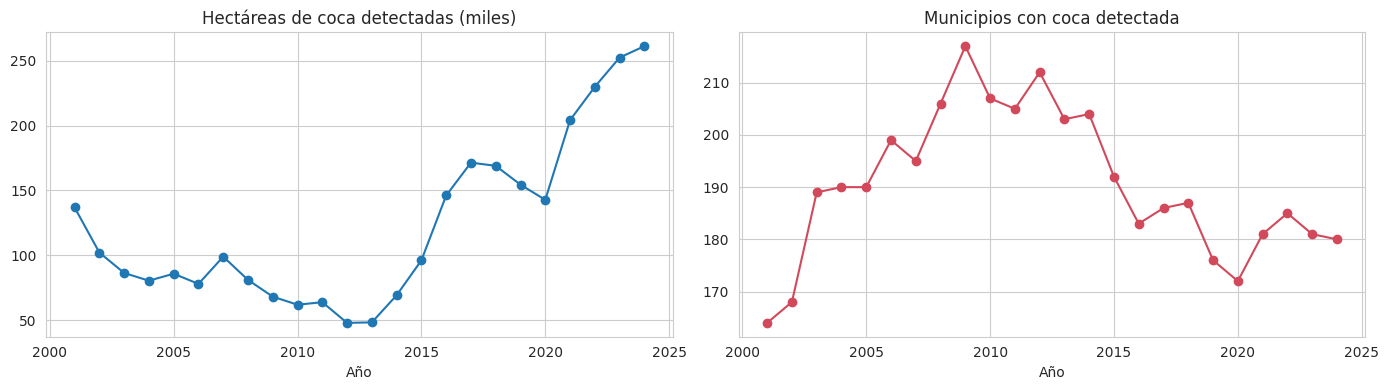

In [23]:
municipios_con_coca = coca[coca['ha_coca'] > 0].groupby('anio')['cod_mpio'].nunique()
hectareas = coca.groupby('anio')['ha_coca'].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(hectareas.index, hectareas / 1000, marker='o')
axes[0].set(title='Hectáreas de coca detectadas (miles)', xlabel='Año')
axes[1].plot(municipios_con_coca.index, municipios_con_coca, marker='o', color='#d1495b')
axes[1].set(title='Municipios con coca detectada', xlabel='Año')
plt.tight_layout()
plt.savefig('outputs/figures/fig00_serie_coca_2001_2024.png', dpi=160, bbox_inches='tight')
plt.show()

### 3. Base de víctimas (un solo corte)

In [24]:
print("Fechas de corte en la base:", df_victimas['fecha_corte'].unique())

victimas = df_victimas.rename(columns={'cod_ciudad_muni': 'cod_mpio', 'vigencia': 'anio', 'per_ocu': 'victimas'})
victimas['cod_mpio'] = victimas['cod_mpio'].str.zfill(5)
victimas['anio'] = victimas['anio'].astype(int)
victimas['victimas'] = pd.to_numeric(victimas['victimas'])

print("Filas sin municipio definido:", (victimas['cod_mpio'] == '00000').sum())
victimas = victimas[victimas['cod_mpio'] != '00000']
victimas = victimas.groupby(['cod_mpio', 'anio'])['victimas'].sum().reset_index()
print("Duplicados en la llave:", victimas.duplicated(subset=['cod_mpio', 'anio']).sum())
print("Víctimas por año:", victimas.groupby('anio')['victimas'].sum().to_dict())
anotar('Víctimas', 'la base original apila 31 fechas de corte', 'se descargó solo el corte 31/08/2026 y se verifica que haya uno',
       'evita inflar las víctimas ~31 veces')
anotar('Víctimas', 'no existe columna de hecho victimizante', 'no se puede separar por tipo de hecho', 'limitación documentada')

Fechas de corte en la base: ['31/08/2026']
Filas sin municipio definido: 3
Duplicados en la llave: 0
Víctimas por año: {2021: 265343, 2022: 379956, 2023: 365232}


### 4. Índice de Pobreza Multidimensional (DANE, censo 2018): tres hojas

In [25]:
ipm = df_ipm.rename(columns={'ID': 'cod_mpio', 'IPM Municipal': 'ipm'})[['cod_mpio', 'ipm']]
ipm_zona = df_ipm_zona.rename(columns={'ID': 'cod_mpio', 'Cabeceras': 'ipm_cabecera',
                                       'IPM Centros poblados y rural disperso': 'ipm_rural'})[['cod_mpio', 'ipm_cabecera', 'ipm_rural']]

nombres_privaciones = {
    'Analfabetismo': 'priv_analfabetismo', 'Bajo logro educativo': 'priv_bajo_logro',
    'Barreras a servicios para cuidado de la primera infancia': 'priv_primera_infancia',
    'Barreras de acceso a servicios de salud': 'priv_acceso_salud', 'Tasa de dependencia': 'priv_dependencia',
    'Hacinamiento crítico': 'priv_hacinamiento', 'Inadecuada eliminación de excretas': 'priv_excretas',
    'Inasistencia escolar': 'priv_inasistencia', 'Material inadecuado de paredes exteriores': 'priv_paredes',
    'Material inadecuado de pisos': 'priv_pisos', 'Rezago escolar': 'priv_rezago',
    'Sin acceso a fuente de agua mejorada': 'priv_agua', 'Sin aseguramiento en salud': 'priv_aseguramiento',
    'Trabajo infantil': 'priv_trabajo_infantil', 'Trabajo informal': 'priv_trabajo_informal'}
privaciones = df_privaciones[df_privaciones['ID'].str.len() == 5].rename(columns={'ID': 'cod_mpio'})
privaciones = privaciones.rename(columns=nombres_privaciones)[['cod_mpio'] + list(nombres_privaciones.values())]

ipm = ipm.merge(ipm_zona, on='cod_mpio', how='left').merge(privaciones, on='cod_mpio', how='left')
columnas_ipm = [c for c in ipm.columns if c != 'cod_mpio']
ipm[columnas_ipm] = ipm[columnas_ipm].apply(pd.to_numeric, errors='coerce')
print("Municipios:", len(ipm), "| duplicados:", ipm.duplicated(subset='cod_mpio').sum())
print("Faltantes:", ipm.isnull().sum().sum())
ipm.head(3)

Municipios: 1122 | duplicados: 0
Faltantes: 20


,cod_mpio,ipm,ipm_cabecera,ipm_rural,priv_analfabetismo,priv_bajo_logro,priv_primera_infancia,priv_acceso_salud,priv_dependencia,priv_hacinamiento,priv_excretas,priv_inasistencia,priv_paredes,priv_pisos,priv_rezago,priv_agua,priv_aseguramiento,priv_trabajo_infantil,priv_trabajo_informal
0,05001,12.80,12.60,22.90,5.00,35.20,1.40,2.60,22.80,5.40,2.00,3.10,0.70,0.20,12.50,1.50,15.90,0.50,71.00
1,05002,40.60,24.10,51.40,18.90,81.70,1.30,3.20,30.20,5.20,23.60,5.00,0.30,1.60,20.30,32.30,8.80,3.60,87.50
2,05004,34.80,13.60,45.20,13.00,66.80,1.30,1.90,37.40,5.40,39.60,2.40,0.80,3.40,13.10,34.40,11.70,1.20,87.60


In [26]:
priv_zona = df_privaciones_zona.copy()
priv_zona.columns = [f"{a}|{b}" for a, b in priv_zona.columns]
priv_zona = priv_zona.rename(columns={priv_zona.columns[0]: 'cod_mpio'})
priv_zona['cod_mpio'] = priv_zona['cod_mpio'].astype(str).str.zfill(5)
rurales = [c for c in priv_zona.columns if 'Centros poblados' in c]
priv_rural = priv_zona[['cod_mpio'] + rurales].copy()
priv_rural[rurales] = priv_rural[rurales].apply(pd.to_numeric, errors='coerce')
priv_rural = priv_rural.merge(df_privaciones[['ID']].rename(columns={'ID': 'cod_mpio'}), on='cod_mpio')

comparacion = privaciones.merge(priv_rural, on='cod_mpio')
correl_total_rural = {}
for nombre_original, nombre_nuevo in nombres_privaciones.items():
    col_rural = [c for c in rurales if c.startswith(nombre_original[:20])][0]
    correl_total_rural[nombre_nuevo] = comparacion[[nombre_nuevo, col_rural]].apply(pd.to_numeric, errors='coerce').corr(method='spearman').iloc[0, 1]
print("Faltantes en las privaciones rurales:", priv_rural[rurales].isnull().sum().sum())
print("Correlación de Spearman entre la privación total y la rural (mediana de las 15):",
      round(np.median(list(correl_total_rural.values())), 2))
pd.Series(correl_total_rural).round(2).sort_values()

Faltantes en las privaciones rurales: 0
Correlación de Spearman entre la privación total y la rural (mediana de las 15): 0.91


priv_pisos              0.26
priv_bajo_logro         0.79
priv_paredes            0.82
priv_acceso_salud       0.87
priv_agua               0.87
priv_excretas           0.88
priv_analfabetismo      0.90
priv_trabajo_infantil   0.91
priv_trabajo_informal   0.92
priv_inasistencia       0.92
priv_dependencia        0.92
priv_hacinamiento       0.93
priv_primera_infancia   0.94
priv_rezago             0.94
priv_aseguramiento      0.95
dtype: float64

In [27]:
anotar('IPM', 'se usaba solo el IPM agregado y un promedio de privaciones', 'cargar IPM, IPM por zona y las 15 privaciones',
       f'{len(columnas_ipm)} variables de pobreza 2018')
anotar('IPM', 'hoja 8 (privaciones por zona, 45 columnas)', 'descartar por redundancia con las privaciones totales',
       f'mediana de correlación total-rural = {np.median(list(correl_total_rural.values())):.2f}')

### 5. Población por área (DANE)

In [28]:
poblacion = df_poblacion.dropna(subset=['MPIO']).rename(columns={'MPIO': 'cod_mpio', 'AÑO': 'anio', 'ÁREA GEOGRÁFICA': 'area', 'TOTAL': 'poblacion'})
poblacion['anio'] = poblacion['anio'].astype(int)
poblacion['poblacion'] = pd.to_numeric(poblacion['poblacion'])
print("Años:", poblacion['anio'].min(), "a", poblacion['anio'].max(), "| áreas:", poblacion['area'].unique())

poblacion = pd.pivot_table(poblacion, index=['cod_mpio', 'anio'], columns='area', values='poblacion', aggfunc='sum').reset_index()
poblacion.columns.name = None
poblacion = poblacion.rename(columns={'Cabecera Municipal': 'pob_cabecera', 'Centros Poblados y Rural Disperso': 'pob_rural', 'Total': 'pob_total'})
poblacion['pct_rural'] = 100 * poblacion['pob_rural'] / poblacion['pob_total']
poblacion = poblacion[poblacion['anio'] <= 2024]
print("Duplicados en la llave:", poblacion.duplicated(subset=['cod_mpio', 'anio']).sum())
poblacion.head(3)

Años: 2018 a 2042 | áreas: ['Cabecera Municipal' 'Centros Poblados y Rural Disperso' 'Total']
Duplicados en la llave: 0


,cod_mpio,anio,pob_cabecera,pob_rural,pob_total,pct_rural
0,05001,2018,"2,382,405.00","44,728.00","2,427,133.00",1.84
1,05001,2019,"2,409,046.00","46,290.00","2,455,336.00",1.89
2,05001,2020,"2,441,882.00","48,073.00","2,489,955.00",1.93


In [29]:
anotar('Población', 'no trae estructura por edad', 'usar población 5-16 del MEN / población total del DANE', 'proporción en edad escolar')

### 6. Municipios PDET

In [30]:
pdet = df_pdet.rename(columns={'cod_muni': 'cod_mpio', 'nom_subreg': 'subregion_pdet'})[['cod_mpio', 'subregion_pdet']]
pdet['cod_mpio'] = pdet['cod_mpio'].str.zfill(5)
print("Municipios PDET:", len(pdet), "| duplicados:", pdet.duplicated(subset='cod_mpio').sum(),
      "| subregiones:", pdet['subregion_pdet'].nunique())

Municipios PDET: 170 | duplicados: 0 | subregiones: 16


### 7. PAE: ¿sirve como variable de contexto departamental?

In [31]:
prueba = men[men['anio'] == 2024][['cod_mpio', 'departamento']].copy()
prueba['variable_departamental'] = prueba.groupby('departamento')['cod_mpio'].transform('count')
dummies = pd.get_dummies(prueba['departamento'], dtype=int)
matriz = np.column_stack([dummies.values, prueba['variable_departamental'].values])
print("Rango de la matriz solo con dummies:", np.linalg.matrix_rank(dummies.values))
print("Rango con dummies + variable departamental:", np.linalg.matrix_rank(matriz))

Rango de la matriz solo con dummies: 33
Rango con dummies + variable departamental: 33


In [32]:
anotar('PAE', 'solo existe por departamento', 'excluir: colinealidad perfecta con las dummies de departamento',
       'el rango de la matriz no cambia al agregarla')
pd.DataFrame(registro)

,Base,Problema,Decisión,Efecto
0,MEN,códigos DANE sin el cero inicial,rellenar con ceros (zfill),sin esto se pierden en la unión
1,MEN,3 filas con código 0 (sin municipio),eliminarlas,"quedan 15,704 filas"
2,MEN,1 valor(es) con separador de miles (Bogotá 2021),quitar la coma antes de convertir a número,en la 2.ª entrega ese valor quedaba vacío
3,Coca,3084 celdas vacías (el SIMCI no escribe ceros),melt a formato largo y vacío = 0 ha,319 municipios x 24 años (2001-2024)
4,Víctimas,la base original apila 31 fechas de corte,se descargó solo el corte 31/08/2026 y se veri...,evita inflar las víctimas ~31 veces
5,Víctimas,no existe columna de hecho victimizante,no se puede separar por tipo de hecho,limitación documentada
6,IPM,se usaba solo el IPM agregado y un promedio de...,"cargar IPM, IPM por zona y las 15 privaciones",18 variables de pobreza 2018
7,IPM,"hoja 8 (privaciones por zona, 45 columnas)",descartar por redundancia con las privaciones ...,mediana de correlación total-rural = 0.91
8,Población,no trae estructura por edad,usar población 5-16 del MEN / población total ...,proporción en edad escolar
9,PAE,solo existe por departamento,excluir: colinealidad perfecta con las dummies...,el rango de la matriz no cambia al agregarla


## Integración de las bases

In [33]:
auditoria = []

def unir(izquierda, derecha, llave, nombre):
    resultado = izquierda.merge(derecha, on=llave, how='left', indicator=True)
    auditoria.append({'Unión': nombre, 'Filas antes': len(izquierda), 'Filas después': len(resultado),
                      'Con pareja': (resultado['_merge'] == 'both').sum(),
                      'Sin pareja': (resultado['_merge'] == 'left_only').sum()})
    return resultado.drop(columns='_merge')

panel = men.copy()
panel = unir(panel, coca, ['cod_mpio', 'anio'], 'MEN + coca (2011-2024)')
panel = unir(panel, victimas, ['cod_mpio', 'anio'], '+ víctimas (2021-2023)')
panel = unir(panel, poblacion, ['cod_mpio', 'anio'], '+ población (2018-2024)')
panel = unir(panel, ipm, ['cod_mpio'], '+ IPM 2018 (3 hojas)')
panel = unir(panel, pdet, ['cod_mpio'], '+ PDET')
pd.DataFrame(auditoria)

,Unión,Filas antes,Filas después,Con pareja,Sin pareja
0,MEN + coca (2011-2024),15704,15704,4461,11243
1,+ víctimas (2021-2023),15704,15704,2988,12716
2,+ población (2018-2024),15704,15704,7850,7854
3,+ IPM 2018 (3 hojas),15704,15704,15703,1
4,+ PDET,15704,15704,2380,13324


In [34]:
panel['ha_coca'] = panel['ha_coca'].fillna(0)
anios_victimas = panel['anio'].isin([2021, 2022, 2023])
print("Municipio-año 2021-2023 sin víctimas registradas:", panel.loc[anios_victimas, 'victimas'].isnull().sum())
panel.loc[anios_victimas, 'victimas'] = panel.loc[anios_victimas, 'victimas'].fillna(0)
panel['pdet'] = np.where(panel['subregion_pdet'].isnull(), 0, 1)

print(f"Panel: {panel['cod_mpio'].nunique()} municipios x {panel['anio'].nunique()} años = {len(panel):,} filas y {panel.shape[1]} columnas")
print("Municipios PDET encontrados:", panel.loc[panel['pdet'] == 1, 'cod_mpio'].nunique(), "de", len(pdet))
print("Municipios sin IPM:", panel.loc[panel['ipm'].isnull(), 'cod_mpio'].nunique())
print("Municipios sin población DANE en 2021-2023:", panel.loc[anios_victimas & panel['pob_total'].isnull(), 'cod_mpio'].nunique())

Municipio-año 2021-2023 sin víctimas registradas: 375
Panel: 1123 municipios x 14 años = 15,704 filas y 67 columnas
Municipios PDET encontrados: 170 de 170
Municipios sin IPM: 1
Municipios sin población DANE en 2021-2023: 0


In [35]:
coca_ancho = pd.pivot_table(coca, index='cod_mpio', columns='anio', values='ha_coca').reset_index()
coca_ancho.columns = ['cod_mpio'] + [f'ha_{a}' for a in coca_ancho.columns[1:]]
coca_ancho.shape

(319, 25)

## Guardar / exportar datos

In [36]:
panel.to_csv('data/processed/panel_municipio_anio.csv', index=False, encoding='utf-8-sig')
coca_ancho.to_csv('data/processed/coca_2001_2024_ancho.csv', index=False, encoding='utf-8-sig')

pd.DataFrame(registro).to_csv('outputs/reports/registro_limpieza.csv', index=False, encoding='utf-8-sig')
pd.DataFrame(auditoria).to_csv('outputs/reports/auditoria_uniones.csv', index=False, encoding='utf-8-sig')
inventario_columnas.to_csv('outputs/reports/inventario_columnas_crudas.csv', index=False, encoding='utf-8-sig')
print("Archivos guardados en data/processed/ y outputs/reports/")

Archivos guardados en data/processed/ y outputs/reports/
